# 음료 병뚜껑 OK/NG 자동 판정 실험

In [1]:
!ls data

calibration  challenge	test  train  validation


In [3]:
!pwd

/home/user1sim/ai_vision/subject9_machinevision


In [18]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

#2-1단계: 결과 저장 폴더 만들기
OUT = Path("outputs/day03/okng")
OUT.mkdir(parents=True, exist_ok=True)

!ls outputs/day03

batch  challenge  contour  feature  morphology	okng  rule


In [6]:
!ls samples/day03/reference

cap_off.jpg  cap_on.jpg


OK 크기: (198, 213, 3)
NG 크기: (198, 213, 3)


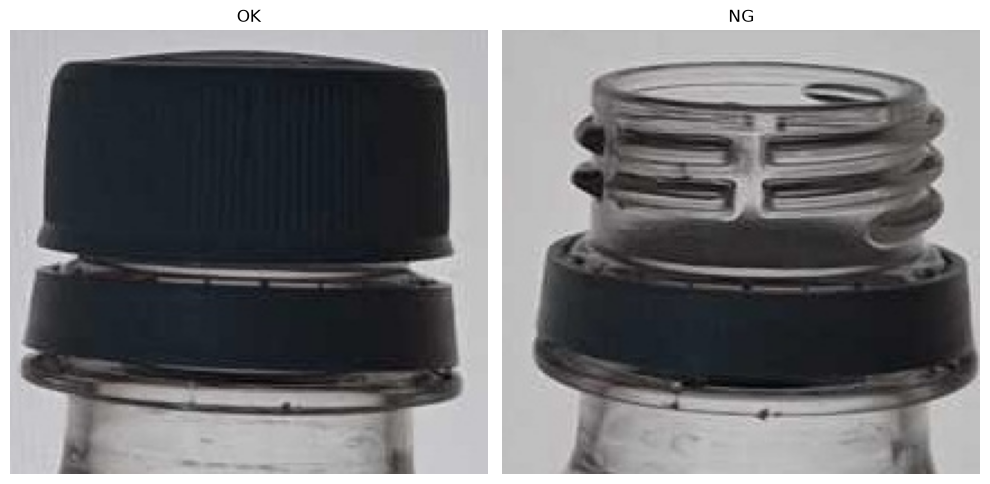

In [13]:
import shutil

REF = Path("samples/day03/reference")
CAL = Path("data/calibration")

# 1) 기준 이미지를 calibration 폴더로 복사 (이름 바꿔서)
ok_path = CAL / "ok_reference_normal_01.jpg"
ng_path = CAL / "ng_reference_normal_01.jpg"
shutil.copy(REF / "cap_on.jpg",  ok_path)
shutil.copy(REF / "cap_off.jpg", ng_path)

# 2) 복사한 파일 읽기
ok_img = cv2.imread(str(ok_path))
ng_img = cv2.imread(str(ng_path))
print("OK 크기:", ok_img.shape)
print("NG 크기:", ng_img.shape)

# 3) 나란히 보기
plt.figure(figsize=(10, 5))
for i, (name, img) in enumerate([("OK", ok_img), ("NG", ng_img)]):
    plt.subplot(1, 2, i + 1)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(name)
    plt.axis("off")
plt.tight_layout()
plt.show()

### img 크기, 사이즈
  OK 크기: (198, 213, 3)
, NG 크기: (198, 213, 3)

OK 크기 (세로, 가로): (198, 213)
NG 크기 (세로, 가로): (198, 213)


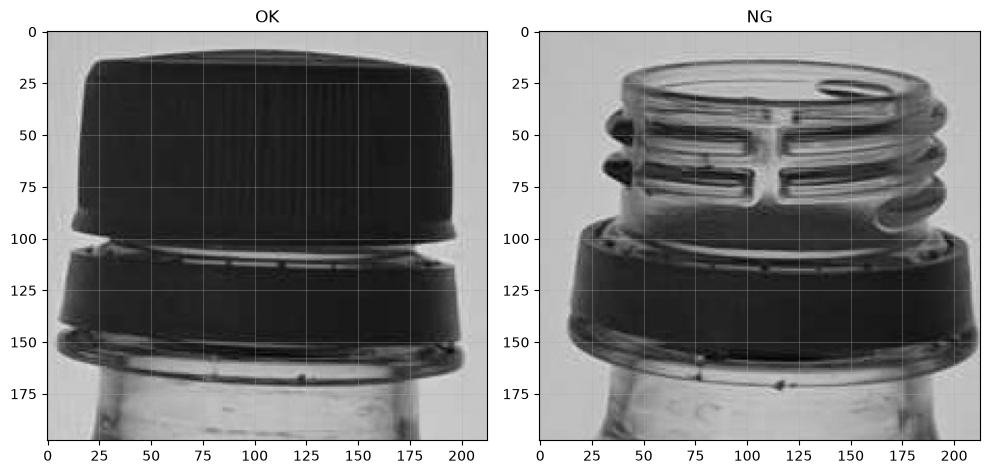

In [14]:
ok_gray = cv2.cvtColor(ok_img, cv2.COLOR_BGR2GRAY)
ng_gray = cv2.cvtColor(ng_img, cv2.COLOR_BGR2GRAY)

print("OK 크기 (세로, 가로):", ok_gray.shape)
print("NG 크기 (세로, 가로):", ng_gray.shape)

plt.figure(figsize=(10, 5))
for i, (name, img) in enumerate([("OK", ok_gray), ("NG", ng_gray)]):
    plt.subplot(1, 2, i + 1)
    plt.imshow(img, cmap="gray", vmin=0, vmax=255)
    plt.title(name)
    plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

- 해당 이미지는 ROI를 측정한 OK, NG 사진임

In [19]:
%pip install pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 36.3 MB/s  0:00:00.9 MB/s eta 0:00:01
Note: you may need to restart the kernel to use updated packages.


차이가 가장 큰 임계값: T=45  (OK 51.4% / NG 18.5% / 차이 33.0%p)
     T   OK_ratio   NG_ratio        gap
16  90  61.694409  36.100441  25.593968


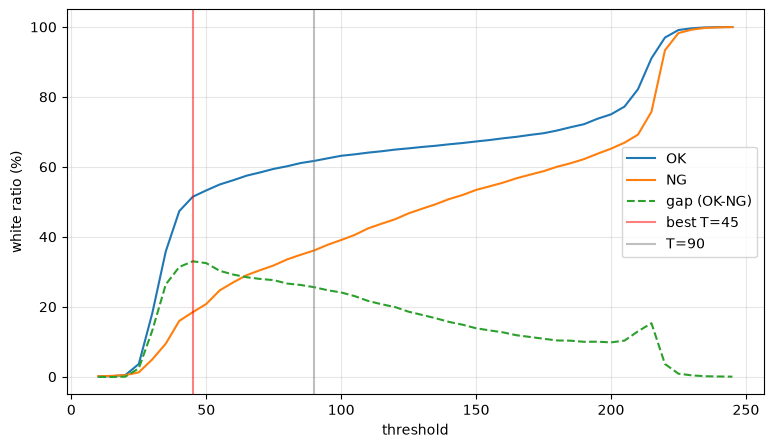

In [20]:
import pandas as pd
rows = []
for t in range(10, 250, 5):
    _, b_ok = cv2.threshold(ok_n, t, 255, cv2.THRESH_BINARY_INV)
    _, b_ng = cv2.threshold(ng_n, t, 255, cv2.THRESH_BINARY_INV)
    ok_r = cv2.countNonZero(b_ok) / b_ok.size * 100
    ng_r = cv2.countNonZero(b_ng) / b_ng.size * 100
    rows.append({"T": t, "OK_ratio": ok_r, "NG_ratio": ng_r, "gap": ok_r - ng_r})

sweep = pd.DataFrame(rows)
best = sweep.loc[sweep["gap"].idxmax()]
print(f"차이가 가장 큰 임계값: T={int(best['T'])}  (OK {best['OK_ratio']:.1f}% / NG {best['NG_ratio']:.1f}% / 차이 {best['gap']:.1f}%p)")
print(sweep[sweep["T"] == 90])

plt.figure(figsize=(9, 5))
plt.plot(sweep["T"], sweep["OK_ratio"], label="OK")
plt.plot(sweep["T"], sweep["NG_ratio"], label="NG")
plt.plot(sweep["T"], sweep["gap"], label="gap (OK-NG)", linestyle="--")
plt.axvline(best["T"], color="red", alpha=0.5, label=f"best T={int(best['T'])}")
plt.axvline(90, color="gray", alpha=0.5, label="T=90")
plt.xlabel("threshold"); plt.ylabel("white ratio (%)")
plt.legend(); plt.grid(alpha=0.3)
plt.savefig(OUT / "threshold_sweep.png")
plt.show()

sweep.to_csv(OUT / "threshold_sweep.csv", index=False)

### 임계값 선택 근거
- 방법: T=10~245를 5 간격으로 스윕, OK−NG 흰 비율 차이 비교
- 결과: 최대 차이 T=45 (33.0%p) / 기존 T=90 (25.6%p)
- 선택: T=50 (차이 약 32.5%p)
- 이유: 45 왼쪽은 차이가 급락(절벽) → 조명 변화 여유를 위해 완만한 쪽으로 이동
- 증거: outputs/okng/threshold_sweep.png, threshold_sweep.csv
- 한계: 기준 이미지 1쌍 기준 → 촬영 데이터로 재검증 필요

OK | T=50      | 흰 픽셀  53.3%
OK | Otsu=121  | 흰 픽셀  65.0%
NG | T=50      | 흰 픽셀  20.8%
NG | Otsu=133  | 흰 픽셀  49.0%


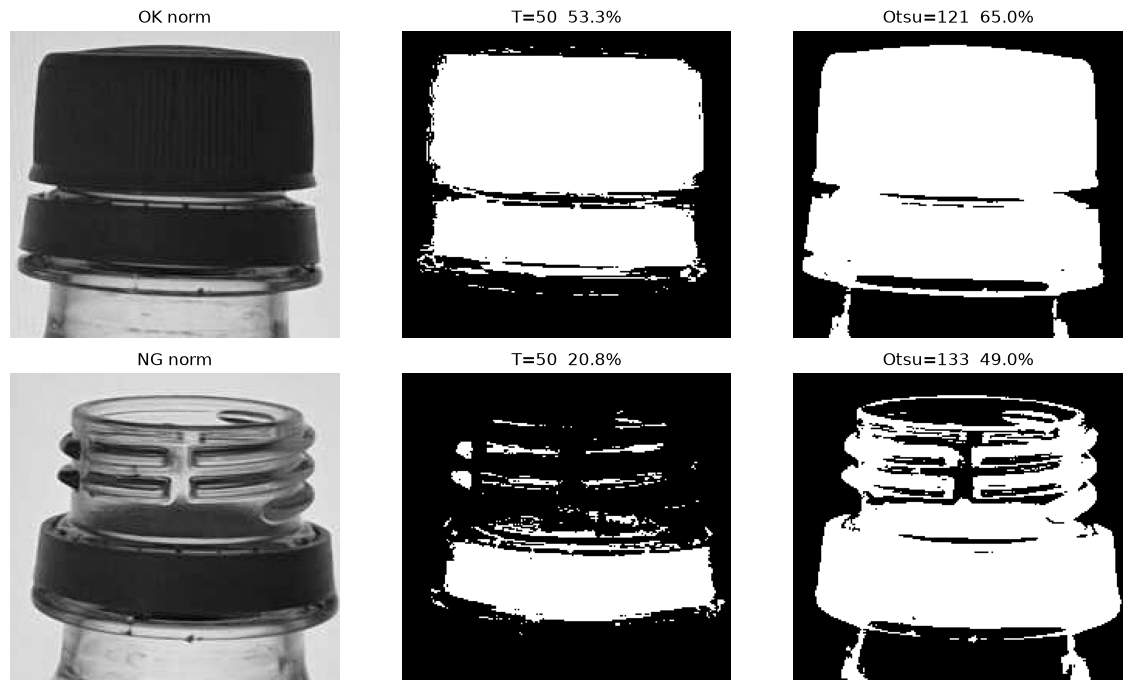

In [22]:
# 대비 보정하고 이진화하기
ok_roi = ok_gray   # 링 포함 전체를 ROI로 사용
ng_roi = ng_gray

ok_n = cv2.normalize(ok_roi, None, 0, 255, cv2.NORM_MINMAX)
ng_n = cv2.normalize(ng_roi, None, 0, 255, cv2.NORM_MINMAX)

T = 50
plt.figure(figsize=(12, 7))
for r, (name, img) in enumerate([("OK", ok_n), ("NG", ng_n)]):
    _, b_fix = cv2.threshold(img, T, 255, cv2.THRESH_BINARY_INV)
    t_otsu, b_otsu = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

    plt.subplot(2, 3, r * 3 + 1)
    plt.imshow(img, cmap="gray", vmin=0, vmax=255); plt.title(f"{name} norm"); plt.axis("off")

    for c, (method, b) in enumerate([(f"T={T}", b_fix), (f"Otsu={t_otsu:.0f}", b_otsu)]):
        ratio = cv2.countNonZero(b) / b.size * 100
        print(f"{name} | {method:9} | 흰 픽셀 {ratio:5.1f}%")
        plt.subplot(2, 3, r * 3 + c + 2)
        plt.imshow(b, cmap="gray"); plt.title(f"{method}  {ratio:.1f}%"); plt.axis("off")

plt.tight_layout()
plt.savefig(OUT / "step6_threshold.png")
plt.show()